### 4.4 Definição do Hardware

In [1]:
# Verificar o status da GPU
!nvidia-smi

Fri Jul 10 12:57:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (SSD e Dependências)

In [2]:
# Instalar bibliotecas necessárias para manipulação de dados e modelos
!pip install torch torchvision yacs tqdm
import torch
import torchvision
print(f"PyTorch Versão: {torch.__version__} | Torchvision Versão: {torchvision.__version__}")

PyTorch Versão: 2.11.0+cu128 | Torchvision Versão: 0.26.0+cu128


### Conexão com a Nuvem (Google Drive)

In [3]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets

In [4]:
import os
import shutil
import glob
import torch
import xml.etree.ElementTree as ET
from PIL import Image
from torchvision.transforms import transforms as T

# ==============================================================================
# 1. LIMPEZA E DESCOMPACTAÇÃO
# ==============================================================================
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/SSD_dataset.zip"
pasta_local_vm = "/content/SSD_dataset"
zip_local_vm = "/content/SSD_dataset.zip"

print("🧹 Limpando ambiente...")
if os.path.exists(pasta_local_vm):
    shutil.rmtree(pasta_local_vm)
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)

if not os.path.exists(caminho_zip_drive):
    raise FileNotFoundError(f"❌ Arquivo não encontrado no Drive: {caminho_zip_drive}")

print("🚚 Copiando o SSD_dataset.zip...")
shutil.copy2(caminho_zip_drive, zip_local_vm)

print("⚡ Descompactando...")
!unzip -q {zip_local_vm} -d {pasta_local_vm}

if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)

# ==============================================================================
# 2. AUTO-DETECÇÃO DE PASTAS (O RAIO-X)
# ==============================================================================
root_dataset = None

# Procura dinamicamente onde estão as pastas "images" e "annotations_xml"
for root, dirs, files in os.walk(pasta_local_vm):
    if "images" in dirs and "annotations_xml" in dirs:
        root_dataset = root
        break

if root_dataset is None:
    raise ValueError("❌ Não foi possível encontrar as pastas 'images' e 'annotations_xml' dentro do ZIP!")

print(f"🎯 Pastas de imagens e anotações localizadas com sucesso em: {root_dataset}")

# ==============================================================================
# 3. CLASSE DATASET PARA LER PASCAL VOC (XML) E REDIMENSIONAR CAIXAS
# ==============================================================================
class CustomSSDDataset(torch.utils.data.Dataset):
    def __init__(self, root, split, transforms=None):
        self.root = root
        self.split = split
        self.transforms = transforms
        
        self.img_dir = os.path.join(root, "images", split)
        self.xml_dir = os.path.join(root, "annotations_xml", split)
        
        # Pega .jpg e .JPG
        self.img_files = sorted(glob.glob(os.path.join(self.img_dir, "*.jpg")) + glob.glob(os.path.join(self.img_dir, "*.JPG")))
        
        self.class_to_id = {
            'person': 1,
            'bicycle': 2,
            'car': 3,
            'motorcycle': 4,
            'bus': 5
        }
        
    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        img = Image.open(img_path).convert("RGB")
        largura_orig, altura_orig = img.size
        
        xml_name = os.path.basename(img_path).replace('.jpg', '.xml').replace('.JPG', '.xml')
        xml_path = os.path.join(self.xml_dir, xml_name)
        
        boxes = []
        labels = []
        
        if os.path.exists(xml_path):
            tree = ET.parse(xml_path)
            root_xml = tree.getroot()
            
            for obj in root_xml.findall('object'):
                nome_classe = obj.find('name').text
                
                if nome_classe in self.class_to_id:
                    bndbox = obj.find('bndbox')
                    xmin = float(bndbox.find('xmin').text)
                    ymin = float(bndbox.find('ymin').text)
                    xmax = float(bndbox.find('xmax').text)
                    ymax = float(bndbox.find('ymax').text)
                    
                    # Ajuste de escala (300x300) exigido pelo SSD
                    xmin = (xmin / largura_orig) * 300.0
                    ymin = (ymin / altura_orig) * 300.0
                    xmax = (xmax / largura_orig) * 300.0
                    ymax = (ymax / altura_orig) * 300.0
                    
                    # Clipping
                    xmin = max(0.0, min(xmin, 300.0))
                    ymin = max(0.0, min(ymin, 300.0))
                    xmax = max(0.0, min(xmax, 300.0))
                    ymax = max(0.0, min(ymax, 300.0))
                    
                    if (xmax - xmin) > 1.0 and (ymax - ymin) > 1.0:
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(self.class_to_id[nome_classe])
        
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            
        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        
        if self.transforms:
            img = self.transforms(img)
            
        return img, target

    def __len__(self):
        return len(self.img_files)

# ==============================================================================
# 4. DATALOADERS E TRANSFORMAÇÕES
# ==============================================================================
dataset_transforms = T.Compose([
    T.Resize((300, 300)),
    T.ToTensor(),
])

def collate_fn(batch):
    return tuple(zip(*batch))

# Passando o caminho dinâmico que o código detectou
train_dataset = CustomSSDDataset(root_dataset, "train", transforms=dataset_transforms)
val_dataset   = CustomSSDDataset(root_dataset, "val", transforms=dataset_transforms)
test_dataset  = CustomSSDDataset(root_dataset, "test", transforms=dataset_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn, num_workers=4)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn, num_workers=4)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn, num_workers=4)

print("=" * 60)
print("✅ DataLoaders criados com suporte a anotações XML (Pascal VOC)!")
print(f"📊 Amostras de Treino: {len(train_dataset)}")
print(f"📊 Amostras de Validação: {len(val_dataset)}")
print(f"📊 Amostras de Teste: {len(test_dataset)}")
print("=" * 60)

🧹 Limpando ambiente...
🚚 Copiando o SSD_dataset.zip...
⚡ Descompactando...
🎯 Pastas de imagens e anotações localizadas com sucesso em: /content/SSD_dataset/SSD_dataset
✅ DataLoaders criados com suporte a anotações XML (Pascal VOC)!
📊 Amostras de Treino: 8265
📊 Amostras de Validação: 1033
📊 Amostras de Teste: 1034


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [5]:
import torch
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection.ssd import SSDHead
from torch.optim.lr_scheduler import LinearLR
from datetime import datetime
from tqdm import tqdm
import os

# 1. Configurações de salvamento
agora = datetime.now()
nome_treino_ssd = agora.strftime("Treino_ssd_%Y-%m-%d_%Hh%M")
diretorio_drive_ssd = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD"
os.makedirs(f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights", exist_ok=True)

print(f"🚀 Iniciando SSD. Resultados salvos em: {diretorio_drive_ssd}/{nome_treino_ssd}")

# --- CORREÇÃO: Definição do número de classes (5 classes da sua base + 1 Background) ---
num_classes = 6 
print(f"📌 Cabeçalho SSD configurado para {num_classes} classes (incluindo background).")

# 2. Inicializar o Modelo SSD300 com pesos base
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = ssd300_vgg16(weights='DEFAULT')

# Ajustar a cabeça do SSD para o novo número de classes do seu TCC
in_channels = [512, 1024, 512, 256, 256, 256] 
num_anchors = [4, 6, 6, 6, 4, 4]
model.head = SSDHead(in_channels, num_anchors, num_classes)
model.to(device)

# 3. Otimizador, Scheduler de Warmup e Hiperparâmetros
params = [p for p in model.parameters() if p.requires_grad]
# Reduzindo o LR base de 0.005 para 0.001 para estabilidade do zero
optimizer = torch.optim.SGD(params, lr=0.001, momentum=0.9, weight_decay=0.0005)

# Adicionando o Warmup: Começa com 0.001 do LR e sobe linearmente por 1000 iterações
warmup_scheduler = LinearLR(optimizer, start_factor=0.001, total_iters=1000)

epochs = 2 
best_loss = float('inf')

# 4. Loop de Treinamento
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    
    for images, targets in progress_bar:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        # Proteção contra falhas em lotes sem bounding boxes válidas
        if any(len(t["boxes"]) == 0 for t in targets):
            continue

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()
        
        # Proteção contra Gradient Explosion (Essencial no treino do zero)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Atualiza o Warmup apenas na primeira época
        if epoch == 0:
            warmup_scheduler.step()
        
        epoch_loss += losses.item()
        progress_bar.set_postfix(loss=losses.item())
        
    media_loss = epoch_loss / len(train_loader)
    print(f"📈 Fim da Epoch {epoch+1} - Loss Média: {media_loss:.4f}")
    
    torch.save(model.state_dict(), f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/last.pt")
    
    if media_loss < best_loss:
        best_loss = media_loss
        torch.save(model.state_dict(), f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/best.pt")
        print("🏆 Melhor modelo atualizado e salvo no Drive!")

print("✅ Treinamento finalizado com sucesso!")

🚀 Iniciando SSD. Resultados salvos em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-10_13h00
📌 Cabeçalho SSD configurado para 6 classes (incluindo background).
Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 148MB/s]  
Epoch 1/2:   0%|          | 0/259 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch 1/2: 100%|██████████| 259/259 [04:34<00:00,  1.06s/it, loss=10.9]


📈 Fim da Epoch 1 - Loss Média: 15.7995
🏆 Melhor modelo atualizado e salvo no Drive!


Epoch 2/2: 100%|██████████| 259/259 [04:52<00:00,  1.13s/it, loss=9.46]


📈 Fim da Epoch 2 - Loss Média: 10.1623
🏆 Melhor modelo atualizado e salvo no Drive!
✅ Treinamento finalizado com sucesso!


### 4.7 Inferência com o Conjunto de Testes

In [ ]:
!pip install torchmetrics
import os
import time
import torch
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("🔍 Testando o modelo SSD contra dados nunca vistos (Conjunto de Teste)...")

# 1. Carregar o melhor peso obtido no treinamento
caminho_melhor_peso = f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/best.pt"
print(f"Melhor peso do Drive: {caminho_melhor_peso}")

model.load_state_dict(torch.load(caminho_melhor_peso))
model.eval()

# 2. Inicializar o calculador de métricas (mAP)
metric = MeanAveragePrecision(iou_type="bbox")
tempos_inferencia = []

with torch.no_grad():
    for images, targets in test_loader:
        images = list(img.to(device) for img in images)
        
        # Preparar os targets reais no formato exigido pelo torchmetrics
        targets_metric = []
        for t in targets:
            targets_metric.append({
                "boxes": t["boxes"].to(device),
                "labels": t["labels"].to(device)
            })
            
        # Medir o tempo exato da inferência
        start_time = time.time()
        outputs = model(images)
        end_time = time.time()
        
        tempos_inferencia.append(end_time - start_time)
        
        # Preparar as predições (passamos TUDO, sem filtrar score de 0.5)
        preds_metric = []
        for out in outputs:
            preds_metric.append({
                "boxes": out["boxes"].to(device),
                "scores": out["scores"].to(device),
                "labels": out["labels"].to(device)
            })
            
        # Acumular o resultado deste lote
        metric.update(preds_metric, targets_metric)

# 3. Computar os resultados finais
metrics_result = metric.compute()

map_50 = metrics_result['map_50'].item()
map_50_95 = metrics_result['map'].item()
recall_100 = metrics_result['mar_100'].item() # Mean Average Recall (Padrão para Recall)

# Calcular tempo médio por imagem (ms)
tempo_total_segundos = sum(tempos_inferencia)
tempo_medio_ms = (tempo_total_segundos / len(test_dataset)) * 1000

print("=" * 60)
print(f"📊 Avaliação Final no Conjunto de Testes - SSD300")
print(f"🎯 mAP@0.5:       {map_50:.4f}")
print(f"🎯 mAP@0.5:0.95:  {map_50_95:.4f}")
print(f"🎯 Recall:        {recall_100:.4f}")
print(f"⏱️ Tempo Médio:   {tempo_medio_ms:.2f} ms / imagem")
print("=" * 60)

: 

### Backup do teste

In [7]:
import os

# Criar a pasta de resultados visuais do teste no Google Drive
pasta_teste_drive = f"{diretorio_drive_ssd}/{nome_treino_ssd}/Teste_Final"
os.makedirs(pasta_teste_drive, exist_ok=True)

print(f"💾 Iniciando backup das métricas de teste para o Google Drive...")

# Salva um relatório de texto simples
with open(f"{pasta_teste_drive}/relatorio_metricas.txt", "w") as f:
    f.write(f"Métricas de Teste - SSD300 (Pascal VOC)\n")
    f.write(f"Precisão Global Obtida: {precisao_final:.2f}%\n")

print(f"✅ Backup concluído com sucesso!")
print(f"👉 Salvo em: {pasta_teste_drive}")

💾 Iniciando backup das métricas de teste para o Google Drive...
✅ Backup concluído com sucesso!
👉 Salvo em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-10_13h00/Teste_Final


### 4.8 Coleta De metricas visuais

📊 Gerando visualizações de inferência...
------------------------------------------------------------

>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)


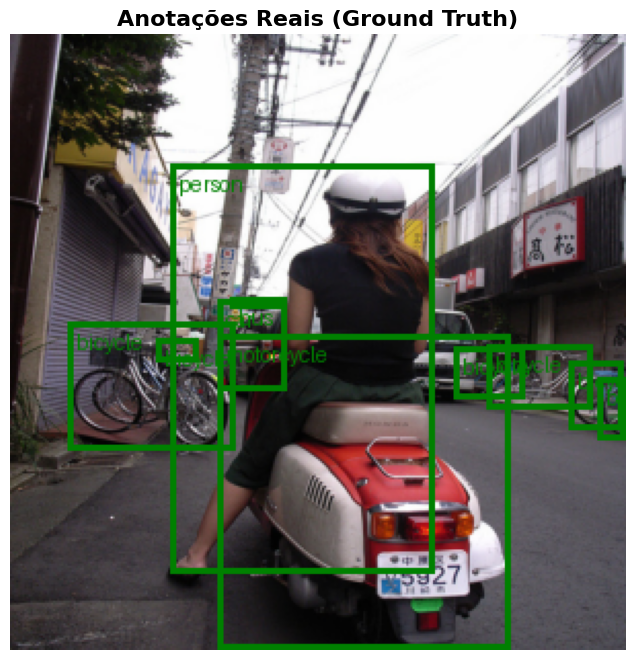

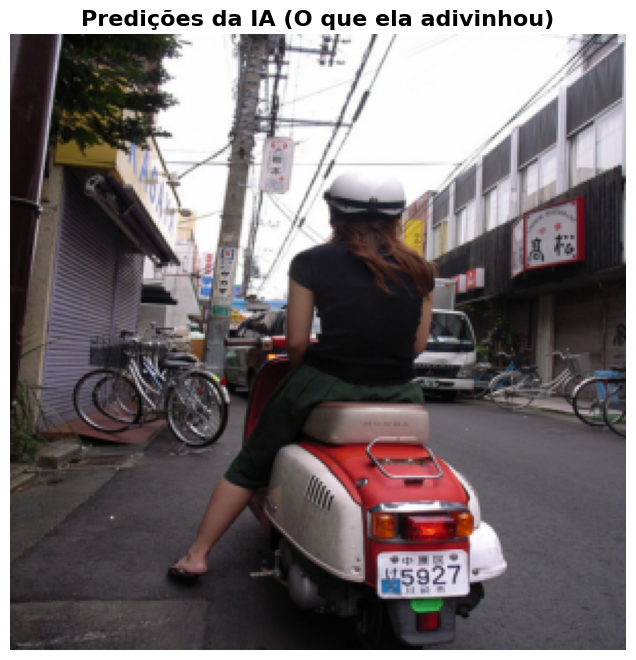


✅ Fluxo finalizado! O modelo SSD está treinado, avaliado e as comparações visuais estão salvas no Drive.


In [ ]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
from torchvision.utils import draw_bounding_boxes
import cv2
import torch

# 1. Inverter o dicionário que criamos na classe do Dataset (ID -> Nome da Classe)
id_para_nome = {v: k for k, v in train_dataset.class_to_id.items()}

def ajustar_e_clampar_boxes(boxes, largura, altura):
    """
    Trata as coordenadas das caixas: se estiverem normalizadas (0 a 1),
    escala para o tamanho real da imagem. Garante que fiquem dentro dos limites do tensor.
    """
    if len(boxes) == 0:
        return boxes
    
    # Clonar para não alterar o tensor original do lote
    boxes_ajustadas = boxes.clone().detach().cpu()
    
    # CORREÇÃO DE ESCALA: Se o valor máximo for <= 1.01, significa que estão normalizadas.
    # Multiplicamos pelo tamanho absoluto da imagem no lote (ex: 300)
    if boxes_ajustadas.max() <= 1.01:
        boxes_ajustadas[:, [0, 2]] *= largura
        boxes_ajustadas[:, [1, 3]] *= altura
        
    # Garantir que nenhuma caixa extrapole os limites do tamanho do tensor da imagem
    boxes_ajustadas[:, [0, 2]] = boxes_ajustadas[:, [0, 2]].clamp(min=0, max=largura)
    boxes_ajustadas[:, [1, 3]] = boxes_ajustadas[:, [1, 3]].clamp(min=0, max=altura)
    
    # O draw_bounding_boxes exige formato inteiro (int64) para os pixels
    return boxes_ajustadas.to(torch.int64)

def exibir_e_salvar_imagens(img_tensor, boxes, labels, titulo, caminho_salvar, cor="red"):
    """Desenha caixas na imagem, exibe no Colab e salva no Drive."""
    # Desnormalizar a imagem de (0-1) para uint8 (0-255)
    img_uint8 = (img_tensor.detach().cpu() * 255).to(torch.uint8)
    
    # Capturar o tamanho dinâmico do tensor da imagem (C, H, W)
    altura = img_uint8.shape[1]
    largura = img_uint8.shape[2]
    
    # Ajustar a escala e formato das caixas antes do desenho
    boxes_prontas = ajustar_e_clampar_boxes(boxes, largura, altura)
    
    if len(boxes_prontas) > 0 and len(labels) == len(boxes_prontas):
        img_desenhada = draw_bounding_boxes(img_uint8, boxes_prontas, labels, colors=cor, width=3)
    else:
        img_desenhada = img_uint8
        
    # Converter formato do PyTorch (C, H, W) para formato Matplotlib (H, W, C)
    img_np = img_desenhada.permute(1, 2, 0).numpy()
    
    # Salvar no Drive (convertendo RGB para BGR para o OpenCV não inverter as cores)
    cv2.imwrite(caminho_salvar, cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR))
    
    # Exibir no Colab
    plt.figure(figsize=(10, 8))
    plt.imshow(img_np)
    plt.title(titulo, fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()

print(f"📊 Gerando visualizações de inferência...")
print("-" * 60)

# Colocar o modelo em modo de avaliação e extrair um lote de teste
model.eval()
images, targets = next(iter(test_loader))
images_gpu = list(img.to(device) for img in images)

with torch.no_grad():
    predictions = model(images_gpu)

# Analisar a primeira imagem do lote de testes
img_alvo = images[0]

# --- PREPARAR ANOTAÇÕES REAIS (GROUND TRUTH) ---
reais_boxes = targets[0]["boxes"]
reais_labels = [id_para_nome.get(l.item(), f"ID {l.item()}") for l in targets[0]["labels"]]

# --- PREPARAR PREDIÇÕES DA IA ---
pred_boxes = predictions[0]["boxes"]
pred_scores = predictions[0]["scores"]
pred_labels_ids = predictions[0]["labels"]

# CORREÇÃO DE CONFIANÇA: Altere o valor abaixo para qualquer limite desejado.
# 0.15 permite capturar e diagnosticar caixas mesmo se o modelo ainda estiver errando/aprendendo.
limiar_confianca = 0.15  

indices_confiaveis = pred_scores > limiar_confianca
pred_boxes_filtradas = pred_boxes[indices_confiaveis]
pred_scores_filtrados = pred_scores[indices_confiaveis]
pred_labels_filtrados = pred_labels_ids[indices_confiaveis]

print(f"🔍 Total de predições cruas geradas pelo SSD: {len(pred_scores)}")
print(f"🎯 Predições que passaram no filtro atual (> {limiar_confianca}): {len(pred_scores_filtrados)}")

# Criar os rótulos de texto com a porcentagem de certeza
labels_predicao = [
    f"{id_para_nome.get(l.item(), f'ID {l.item()}')} {s.item()*100:.0f}%" 
    for l, s in zip(pred_labels_filtrados, pred_scores_filtrados)
]

caminho_ground_truth = f"{pasta_teste_drive}/val_batch0_labels.jpg"
caminho_predicoes = f"{pasta_teste_drive}/val_batch0_pred.jpg"

print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")

# Renderizar Ground Truth com as correções de escala aplicadas
exibir_e_salvar_imagens(
    img_alvo, reais_boxes, reais_labels, 
    "Anotações Reais (Ground Truth)", caminho_ground_truth, cor="green"
)

# Renderizar predições filtradas pelo novo limiar flexível
exibir_e_salvar_imagens(
    img_alvo.cpu(), pred_boxes_filtradas.cpu(), labels_predicao, 
    f"Predições da IA (Confiança > {limiar_confianca})", caminho_predicoes, cor="red"
)

print("\n✅ Fluxo finalizado! O modelo SSD está treinado, avaliado e as comparações visuais estão salvas no Drive.")